In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [10]:
df = pd.read_csv('crop_yield.csv')

In [11]:
df.head(10)

,FARM_ID,CROP_TYPE,YIELD_KG,AREA_ACRES,HARVEST_DATE,DISTRICT,SEASON,FERTILIZER_USED,YIELD_VALUE
0,F001,Wheat,1500.0,4.0,01/01/2023,Sialkot,Rabi,Yes,30000
1,F002,Wheat,1500.0,5.0,02/01/2023,Multan,Rabi,No,30000
2,F003,Wheat,2500.0,5.0,03/01/2023,Faisalabad,Rabi,Yes,50000
3,F004,Wheat,1500.0,NaN,04/01/2023,Multan,Rabi,Yes,30000
4,F005,Rice,1500.0,4.0,05/01/2023,Faisalabad,Rabi,No,30000
5,F006,Rice,2000.0,6.0,06/01/2023,Faisalabad,Rabi,Yes,40000
6,F007,Maize,1500.0,6.0,07/01/2023,Faisalabad,Rabi,No,30000
7,F008,Wheat,1500.0,5.0,08/01/2023,Lahore,Rabi,No,30000
8,F009,Wheat,2000.0,5.0,09/01/2023,Faisalabad,Rabi,Yes,40000
9,F010,Wheat,1500.0,3.0,10/01/2023,Faisalabad,Rabi,Yes,30000


In [12]:
df.isnull().sum()

,0
FARM_ID,0
CROP_TYPE,0
YIELD_KG,330
AREA_ACRES,144
HARVEST_DATE,0
DISTRICT,126
SEASON,0
FERTILIZER_USED,318
YIELD_VALUE,0


In [13]:
df.dtypes

,0
FARM_ID,object
CROP_TYPE,object
YIELD_KG,float64
AREA_ACRES,float64
HARVEST_DATE,object
DISTRICT,object
SEASON,object
FERTILIZER_USED,object
YIELD_VALUE,int64


In [14]:
df.describe()

,YIELD_KG,AREA_ACRES,YIELD_VALUE
count,2670.000000,2856.000000,3000.000000
mean,2014.232210,4.420168,39657.780000
std,407.846962,0.979259,8405.078755
min,1500.000000,3.000000,20068.000000
25%,1500.000000,4.000000,30000.000000
50%,2000.000000,4.000000,40000.000000
75%,2500.000000,5.000000,50000.000000
max,2500.000000,6.000000,50000.000000


In [15]:
df.select_dtypes(include=['object']).describe()

,FARM_ID,CROP_TYPE,HARVEST_DATE,DISTRICT,SEASON,FERTILIZER_USED
count,3000,3000,3000,2874,3000,2682
unique,3000,4,3000,4,2,2
top,F001,Wheat,01/01/2023,Faisalabad,Rabi,Yes
freq,1,1158,1,936,1528,1776


In [16]:
df = df.dropna(subset=['YIELD_KG'])
df.shape

(2670, 9)

In [17]:
df['AREA_ACRES'] = df['AREA_ACRES'].fillna(df['AREA_ACRES'].mean())

In [18]:
df['DISTRICT'] = df['DISTRICT'].fillna('Unknown')

In [19]:
df['FERTILIZER_USED'] = df['FERTILIZER_USED'].fillna('No')

In [20]:
df['YIELD_VALUE'] = df['YIELD_VALUE'].fillna(df['YIELD_VALUE'].mean())

In [21]:
df['HARVEST_DATE'] = pd.to_datetime(df['HARVEST_DATE'], format='%d/%m/%Y')

In [22]:
df['FARM_ID'] = df['FARM_ID'].str.replace('F', '')
df['FARM_ID'] = df['FARM_ID'].astype(int)

In [23]:
df.isnull().sum()

,0
FARM_ID,0
CROP_TYPE,0
YIELD_KG,0
AREA_ACRES,0
HARVEST_DATE,0
DISTRICT,0
SEASON,0
FERTILIZER_USED,0
YIELD_VALUE,0


In [24]:
df.dtypes

,0
FARM_ID,int64
CROP_TYPE,object
YIELD_KG,float64
AREA_ACRES,float64
HARVEST_DATE,datetime64[ns]
DISTRICT,object
SEASON,object
FERTILIZER_USED,object
YIELD_VALUE,int64


In [25]:
total_yield = df.groupby('CROP_TYPE')['YIELD_KG'].sum()
total_yield

,YIELD_KG
CROP_TYPE,
Maize,1112500.0
Rice,1638000.0
Sugarcane,592000.0
Wheat,2035500.0


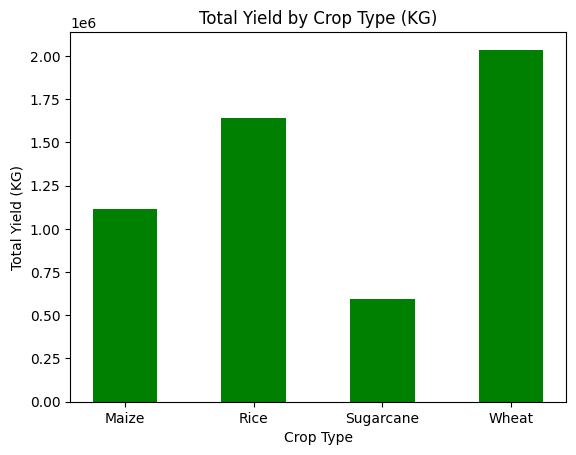

In [26]:
plt.bar(total_yield.index, total_yield.values, color='green', width=0.5)
plt.xlabel('Crop Type')
plt.ylabel('Total Yield (KG)')
plt.title('Total Yield by Crop Type (KG)')
plt.show()

In [27]:
pivot = df.pivot_table(values='YIELD_KG', index='HARVEST_DATE', aggfunc='sum')
pivot

,YIELD_KG
HARVEST_DATE,
2023-01-01,1500.0
2023-01-02,1500.0
2023-01-03,2500.0
2023-01-04,1500.0
2023-01-05,1500.0
...,...
2031-03-15,1500.0
2031-03-16,2000.0
2031-03-17,2000.0
